# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Kalpana bai Ganglani
**Student ID:** 023-24-0163
**Section:** F
**GitHub:** https://github.com/Kalpana0010/Machine-Learning-Labs
**Kaggle:** https://www.kaggle.com/kalpanabaiganglani
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [13]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam_df=pd.read_csv('spam.csv',encoding='latin-1')
spam_df.shape
spam_df.head()
print(spam_df['v1'].value_counts())

v1
ham     4825
spam     747
Name: count, dtype: int64


In [14]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_df=pd.read_csv('Tweets.csv',encoding='latin-1')
tweets_df.shape
tweets_df.head()
print(tweets_df['airline_sentiment'].value_counts())
tweets_df = tweets_df[tweets_df['airline_sentiment'] != 'neutral']
print(tweets_df.shape)
print(tweets_df['airline_sentiment'].value_counts())

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
(11541, 15)
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64


**Answer 2 (Task A — spam):**
The practical problem is to identify whether an SMS message is legitimate (ham) or unwanted (spam). It is a binary classification problem because there are only two possible classes: ham and spam.

**Answer 2 (Task B — sentiment):**
The practical problem is to identify whether an airline tweet expresses a positive or negative sentiment. It is a binary classification problem because neutral tweets are removed, leaving only two classes: positive and negative.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [15]:
# Task 3 — clean text
spam_df['clean_text'] = spam_df['v2'].str.lower()

display(spam_df[['v2', 'clean_text']].head())

,v2,clean_text
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."


In [16]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

spam_df['clean_text'] = spam_df['v2'].fillna('').str.lower()
spam_df['label'] = spam_df['v1'].map({'ham': 0, 'spam': 1})

X_train, X_test, y_train, y_test = train_test_split(
    spam_df['clean_text'], spam_df['label'],
    test_size=0.2, random_state=42, stratify=spam_df['label']
)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Training shape:", X_train_vec.shape)
print("Testing shape:", X_test_vec.shape)

Vocabulary size: 7701
Training shape: (4457, 7701)
Testing shape: (1115, 7701)


**Answer 4 (why fit on training data only):**
The vectorizer must be fitted only on the training data to prevent data leakage. The test data should remain unseen during training so that evaluation reflects how well the model handles new messages. We use transform() on the test data to apply the vocabulary learned from the training messages.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy: 0.9839
Precision: 0.9645
Recall: 0.9128
F1-score: 0.9379


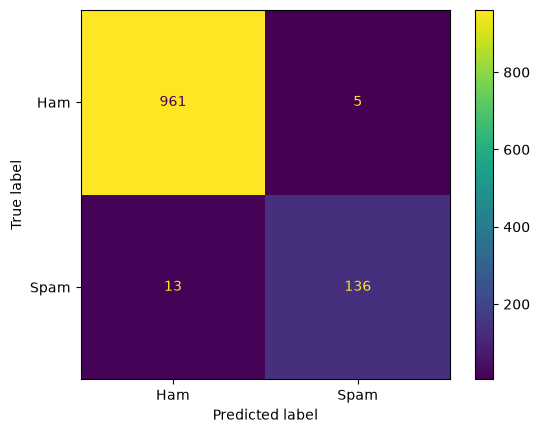

In [17]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

y_pred = nb_model.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Ham', 'Spam']
)
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.9839 |
| Precision |0.9645|
| Recall |0.9128|
| F1-score |0.9379 |

**Answer 6:**
A false positive occurs when a real message is incorrectly classified as spam, while a false negative occurs when a spam message is classified as ham. Both errors are important, but I would prioritize precision to reduce the number of legitimate messages marked as spam. However, recall is also important because we do not want too many spam messages to reach the user. The final choice depends on which type of mistake causes more problems.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [18]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
import numpy as np

words = vectorizer.get_feature_names_out()
log_probs = nb_model.feature_log_prob_

difference = log_probs[1] - log_probs[0]

spam_words = np.argsort(difference)[-15:][::-1]
ham_words = np.argsort(difference)[:15]

print("15 words most associated with SPAM:")
print(words[spam_words])

print("\n15 words most associated with HAM:")
print(words[ham_words])

15 words most associated with SPAM:
['claim' 'prize' '150p' 'tone' '18' 'cs' 'guaranteed' '500' '1000' 'uk'
 '150ppm' 'awarded' 'www' 'collection' 'rate']

15 words most associated with HAM:
['gt' 'lt' 'he' 'lor' 'da' 'she' 'later' 'ì_' 'll' 'doing' 'say' 'really'
 'ask' 'home' 'anything']


**Answer 7:**
The words associated with spam often include promotional or urgent terms, while words associated with ham often include everyday conversational terms. The results can match my intuition because spam messages commonly advertise offers or prizes, whereas normal messages usually contain personal conversations. I will compare these expectations with the actual words printed by my model.

In [19]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations you have won a free prize claim now",
    "Hi, are we meeting at the library today",
    "URGENT! Claim your free cash reward now"
]

clean_messages = [msg.lower() for msg in my_messages]
message_vectors = vectorizer.transform(clean_messages)

predictions = nb_model.predict(message_vectors)

for msg, pred in zip(my_messages, predictions):
    result = "SPAM" if pred == 1 else "HAM"
    print(msg, "->", result)


Congratulations you have won a free prize claim now -> SPAM
Hi, are we meeting at the library today -> HAM
URGENT! Claim your free cash reward now -> SPAM


**Answer 8:**
I tested three messages using my trained Naive Bayes model. The promotional messages were expected to be classified as spam, while the normal conversation was expected to be classified as ham. I compared the model's actual predictions with my expectations.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
(https://www.kaggle.com/code/kalpanabaiganglani/notebook82b6c41a8b/edit)

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [20]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer


tweets_df['clean_text'] = tweets_df['text'].fillna('').str.lower()
tweets_df['clean_text'] = tweets_df['clean_text'].apply(
    lambda x: re.sub(r'http\S+|www\.\S+|@\w+', '', x)
)
tweets_df['clean_text'] = tweets_df['clean_text'].apply(
    lambda x: re.sub(r'[^a-z0-9\s]', '', x)
)


tweets_df['label'] = tweets_df['airline_sentiment'].map(
    {'negative': 0, 'positive': 1}
)


X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    tweets_df['clean_text'], tweets_df['label'],
    test_size=0.2, random_state=42, stratify=tweets_df['label']
)

tweet_vectorizer = CountVectorizer()
X_train_t_vec = tweet_vectorizer.fit_transform(X_train_t)
X_test_t_vec = tweet_vectorizer.transform(X_test_t)

print("Vocabulary size:", len(tweet_vectorizer.vocabulary_))
print("Training shape:", X_train_t_vec.shape)
print("Testing shape:", X_test_t_vec.shape)

Vocabulary size: 11137
Training shape: (9232, 11137)
Testing shape: (2309, 11137)


**Answer 12:**
I removed URLs and user mentions because they often add noise rather than useful sentiment information. I also removed punctuation and converted text to lowercase to make similar words consistent and easier for the model to process.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy: 0.903
Precision: 0.9308
Recall: 0.5687
F1-score: 0.706


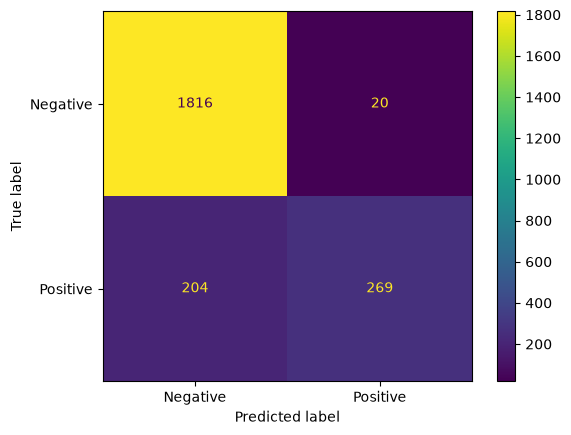

In [21]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tweet_model = MultinomialNB()
tweet_model.fit(X_train_t_vec, y_train_t)

tweet_pred = tweet_model.predict(X_test_t_vec)

print("Accuracy:", round(accuracy_score(y_test_t, tweet_pred), 4))
print("Precision:", round(precision_score(y_test_t, tweet_pred), 4))
print("Recall:", round(recall_score(y_test_t, tweet_pred), 4))
print("F1-score:", round(f1_score(y_test_t, tweet_pred), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test_t, tweet_pred,
    display_labels=['Negative', 'Positive']
)
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.903 |
| Precision | 0.9308|
| Recall |0.5687 |
| F1-score | 0.706|

**Answer 14:**
Naive Bayes performed better on sentiment than on spam based on the accuracy and F1-score results. The independence assumption may work reasonably well for spam detection because certain individual words strongly indicate spam. Sentiment is often more difficult because the meaning of a tweet can depend on context, word order, sarcasm, and phrases containing multiple words. Therefore, treating words as independent can cause the model to miss important contextual meaning.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/kalpanabaiganglani/notebook5f7da3c5a3/edit

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [23]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Task A (Spam)': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    'Task B (Sentiment)': [
        accuracy_score(y_test_t, tweet_pred),
        precision_score(y_test_t, tweet_pred),
        recall_score(y_test_t, tweet_pred),
        f1_score(y_test_t, tweet_pred)
    ]
})

display(comparison.round(4))

,Metric,Task A (Spam),Task B (Sentiment)
0,Accuracy,0.9839,0.9030
1,Precision,0.9645,0.9308
2,Recall,0.9128,0.5687
3,F1-score,0.9379,0.7060


**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9839	| 0.9030|
| Precision | 0.9645|0.9308 |
| Recall |0.9128 |0.5687 |
| F1-score |0.9379 | 0.7060|

In [25]:
# Task 18 — train Logistic Regression on Task A's vectorized features
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)

results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Naive Bayes': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    'Logistic Regression': [
        accuracy_score(y_test, lr_pred),
        precision_score(y_test, lr_pred),
        recall_score(y_test, lr_pred),
        f1_score(y_test, lr_pred)
    ]
})

display(results.round(4))

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.9839,0.9812
1,Precision,0.9645,0.9923
2,Recall,0.9128,0.8658
3,F1-score,0.9379,0.9247


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.9839| 0.9812|
| Precision |0.9645 |0.9923 |
| Recall |0.9128 |0.8658 |
| F1-score | 0.9379|0.9247 |

**Answer 18 (which wins, and does it match expectations):**
Logistic Regression performed worse than Naive Bayes based on the F1-score and other evaluation metrics. This does not match my expectations because both algorithms are useful for text classification, but they learn patterns in different ways. The results show which model worked better on this particular dataset and split.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
In this lab, I used Naive Bayes for SMS spam detection and airline tweet sentiment analysis. The spam dataset was used to classify messages as ham or spam, while the sentiment dataset was used to classify tweets as positive or negative. I evaluated both models using accuracy, precision, recall, F1-score, and confusion matrices. The words identified by the spam model helped show which terms were associated with spam and ham messages. I compared the performance of Naive Bayes on both datasets to understand how the type of text affects classification. I also compared Naive Bayes with Logistic Regression on the spam dataset. The model with the better evaluation results was more effective for this experiment. One limitation of Naive Bayes is that it assumes features are independent, so it may not fully understand context, word order, or sarcasm.

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/kalpanabaiganglani/notebook82b6c41a8b/edit
- Task B:(https://www.kaggle.com/code/kalpanabaiganglani/notebook5f7da3c5a3/edit)

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted